In [43]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression 
from sklearn.linear_model import Ridge,Lasso
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from scipy.special import expit,softmax


In [44]:
# 데이터 생성 - Species,Weight,Length,Diagonal,Height,Width
fish = pd.read_csv('data/fish_logistic.csv')
# Species 중복제거 출력
print(pd.unique(fish['Species']))

['Bream' 'Roach' 'Whitefish' 'Parkki' 'Perch' 'Pike' 'Smelt']


In [45]:
data = fish[['Weight','Length','Diagonal','Height','Width']]
label = fish['Species']  # 데이터 만들기

In [46]:
# train데이터, test데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)


In [47]:
# 데이터 전처리 스케일 조정, 정규화 작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [48]:
# 확률적 경사하강법 함수사용 / max_iter = 10 제외 / for문으로 사용
sc = SGDClassifier(loss='log_loss', random_state=42)
train_score=[]
test_score=[]

In [49]:
# fit을 먼저 사용하지 않기에 정답을 모두 알지 못함.
# 그래서 모든 정답을 알려줘야 함.
classes = np.unique(train_label)
for _ in range(0,300):   
    # partial_fit 함수는 데이터의 일부만 전달될 수 있다고 가정하기에, 클래스(결과값)개수를 꼭 넘겨야 함.
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

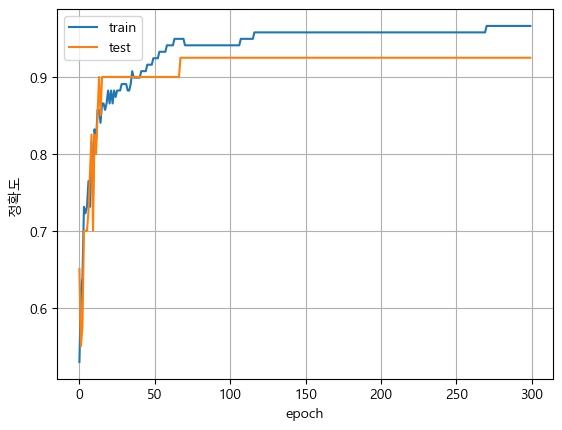

In [50]:
# plt.figure(figsize=(10,6)) #그래프 가로세로크기설정
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('epoch')
plt.ylabel('정확도')
plt.legend(['train','test'])
plt.grid()
plt.show()


In [51]:
# 30-200 사이의 그래프를 보면서, 반복횟수를 조정해서 최상의 조건을 찾음. / tol=None 조기종료 하지 않기   
sc = SGDClassifier(loss='log_loss', max_iter=100, tol=None, random_state=42)
sc.fit(train_scaled,train_label) 
print(sc.score(train_scaled,train_label))
print(sc.score(test_scaled,test_label))


0.957983193277311
0.925


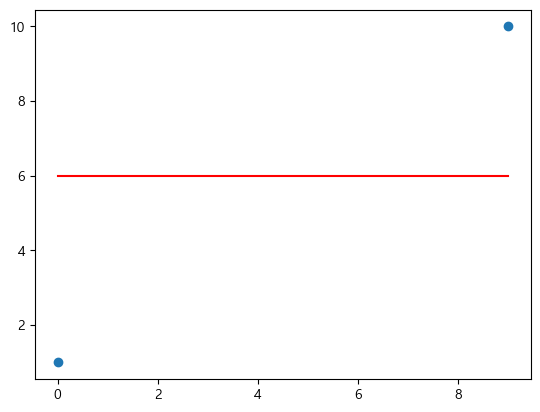

In [52]:
alist = list(range(10))
plt.scatter([0,9],[1,10])
plt.plot(alist,[6]*len(alist),color='r')
plt.show()